![Multimodal RAG](../diagrams/21-multimodal-rag.png)

### Multimodal RAG with LangGraph and Gemini
Normal RAG turns a PDF into **text** chunks, so tables, charts and figures are lost or garbled.
**Multimodal (page-image) RAG** keeps each PDF page as an **image**:

1. Render every page to an image.
2. Embed each page image with **Gemini Embedding 2** (text and images share one vector space).
3. Embed the user's *text* question and find the closest page images.
4. Give those page images to a vision LLM, which reads the tables and figures to answer.

**Public data used:** the paper *Attention Is All You Need* (arXiv 1706.03762, free to download). It has a figure, tables and equations, which is exactly where text-only RAG struggles.

> Larger public datasets for going further: [ViDoRe](https://arxiv.org/pdf/2407.01449) (page retrieval benchmark), [MMDocIR](https://arxiv.org/html/2501.08828v2) (long documents) and MMDocRAG (multimodal document QA).

#### 1. Setup

In [1]:
import base64, time
import numpy as np
import pymupdf  # PyMuPDF
import requests
from dotenv import load_dotenv
from google import genai
from google.genai import types
from IPython.display import Image, display
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI

load_dotenv()  # GEMINI_API_KEY and OPENAI_API_KEY from .env

gemini = genai.Client()  # reads GEMINI_API_KEY
EMBED_MODEL = "gemini-embedding-2"
llm = ChatOpenAI(model="gpt-4.1-mini", temperature=0)  # vision-capable answer model

#### 2. Download the public PDF and render each page as an image

15 pages rendered


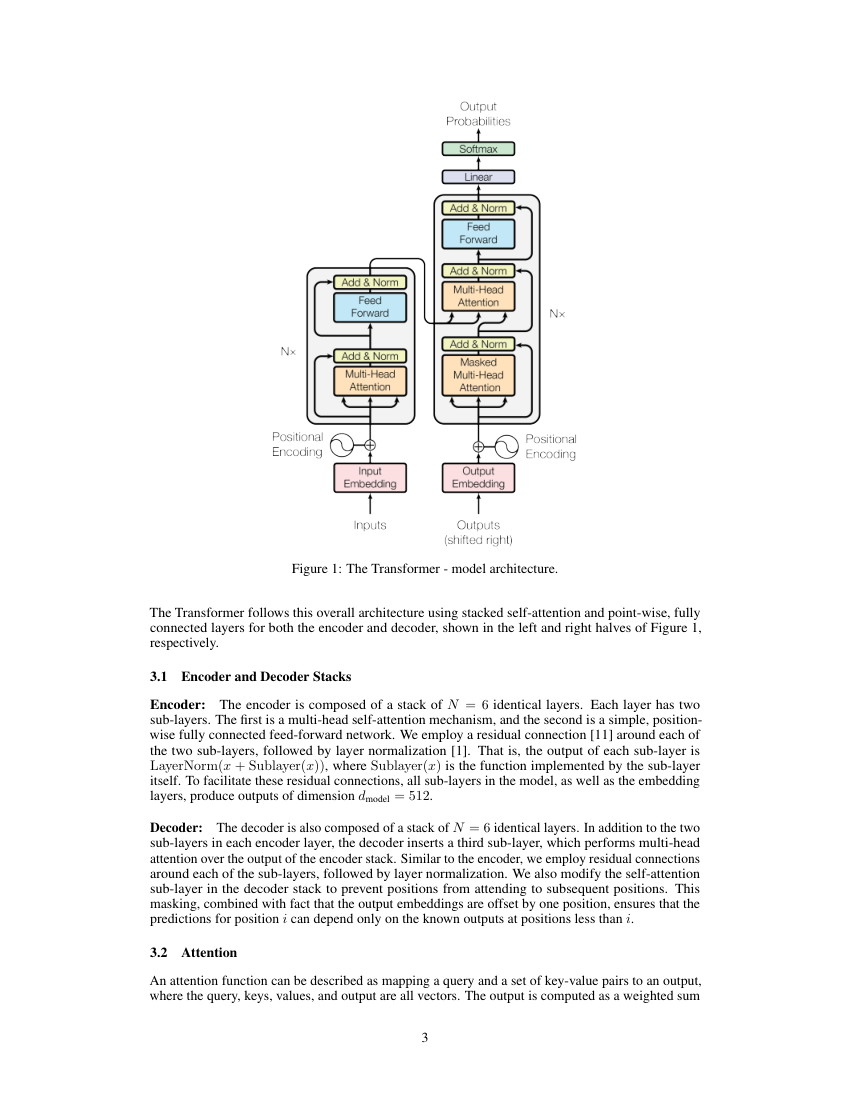

In [2]:
pdf_bytes = requests.get(
    "https://arxiv.org/pdf/1706.03762",
    headers={"User-Agent": "langgraph-teaching-notebooks/1.0"},
    timeout=60,
).content

doc = pymupdf.open(stream=pdf_bytes, filetype="pdf")
pages = [page.get_pixmap(dpi=100).tobytes("png") for page in doc]  # list of PNG bytes
print(f"{len(pages)} pages rendered")
display(Image(data=pages[2], width=450))  # page 3 contains the Transformer architecture figure

#### 3. Embed every page image
`embed_content` takes an image `Part`. Embed **one page per call**: passing several images in one call returns a single combined embedding.

In [3]:
def embed_with_retry(contents, tries=5):
    for attempt in range(tries):
        try:
            return gemini.models.embed_content(model=EMBED_MODEL, contents=contents).embeddings[0].values
        except Exception as e:  # rate limit: back off and retry
            if attempt == tries - 1:
                raise
            time.sleep(5 * (attempt + 1))

page_vectors = np.array([
    embed_with_retry([types.Part.from_bytes(data=png, mime_type="image/png")])
    for png in pages
])
page_vectors /= np.linalg.norm(page_vectors, axis=1, keepdims=True)  # normalise -> dot product = cosine similarity
page_vectors.shape

(15, 3072)

#### 4. Retrieve: text question in, page images out

top pages (0-indexed): [7, 8]


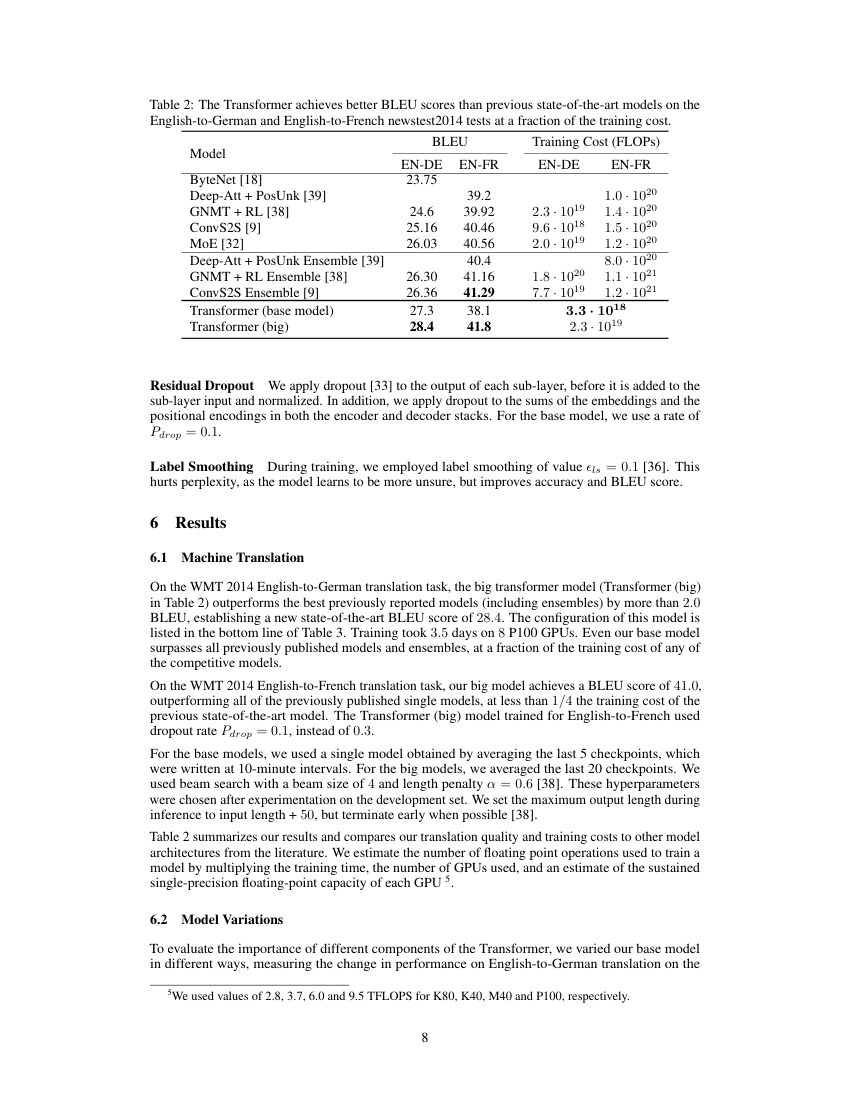

In [4]:
def retrieve_pages(question: str, k: int = 2) -> list[int]:
    q = np.array(embed_with_retry([question]))
    q /= np.linalg.norm(q)
    scores = page_vectors @ q
    return [int(i) for i in np.argsort(scores)[::-1][:k]]

top = retrieve_pages("What BLEU score did the Transformer get on English-to-German translation?")
print("top pages (0-indexed):", top)
display(Image(data=pages[top[0]], width=450))

#### 5. The LangGraph: `retrieve` -> `answer`
The `answer` node builds a message that mixes **text and images**, using LangChain's standard `image` content block (the same block works for OpenAI, Gemini and Anthropic models).

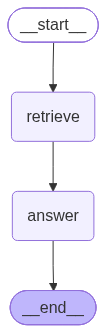

In [5]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    question: str
    page_ids: list[int]
    answer: str

def retrieve(state: State):
    return {"page_ids": retrieve_pages(state["question"], k=2)}

def answer(state: State):
    content = [{"type": "text", "text": (
        "Answer the question using only the document pages shown as images. "
        "Mention which page the answer came from if you can.\n\n"
        f"Question: {state['question']}")}]
    for i in state["page_ids"]:
        content.append({"type": "image", "base64": base64.b64encode(pages[i]).decode(), "mime_type": "image/png"})
    return {"answer": llm.invoke([HumanMessage(content=content)]).text}

builder = StateGraph(State)
builder.add_node("retrieve", retrieve)
builder.add_node("answer", answer)
builder.add_edge(START, "retrieve")
builder.add_edge("retrieve", "answer")
builder.add_edge("answer", END)
graph = builder.compile()

display(Image(data=graph.get_graph().draw_mermaid_png()))

#### 6. Ask questions that need tables and figures

In [6]:
result = graph.invoke({"question": "What BLEU score did the big Transformer get on English-to-German translation, and how does it compare to the previous best models?"})
print("Retrieved pages (0-indexed):", result["page_ids"])
print(result["answer"])

Retrieved pages (0-indexed): [7, 8]
The big Transformer model achieved a BLEU score of 28.4 on the English-to-German translation task. This score outperforms the best previously reported models (including ensembles) by more than 2.0 BLEU, establishing a new state-of-the-art BLEU score. The previous best models had BLEU scores ranging from 23.75 to 26.36, with the best ensemble model (ConvS2S Ensemble) achieving 26.36 BLEU. 

This information is found on page 8 in the paragraph under section 6.1 Machine Translation and in Table 2.


In [7]:
result = graph.invoke({"question": "Describe the Transformer model architecture figure: what are the main blocks in the encoder and the decoder?"})
print("Retrieved pages (0-indexed):", result["page_ids"])
print(result["answer"])

Retrieved pages (0-indexed): [2, 1]
The Transformer model architecture figure shows the encoder and decoder stacks with their main blocks:

- Encoder: Composed of a stack of N=6 identical layers. Each layer has two sub-layers:
  1. Multi-head self-attention mechanism.
  2. Fully connected feed-forward network.
  Each sub-layer is followed by residual connections and layer normalization.

- Decoder: Also composed of a stack of N=6 identical layers. Each decoder layer has three sub-layers:
  1. Multi-head self-attention mechanism (modified with masking to prevent positions from attending to subsequent positions).
  2. Multi-head attention over the output of the encoder stack.
  3. Fully connected feed-forward network.
  Like the encoder, residual connections and layer normalization are applied around each sub-layer.

This description corresponds to the left and right halves of the figure, where the encoder stack is on the left and the decoder stack on the right.

This information is from

#### 7. Optional: swap the answer model to Gemini
Only the `llm` changes. Note that a free-tier Gemini key has a small daily request limit, which is why this notebook answers with OpenAI by default.

In [8]:
from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash", temperature=0)
result = graph.invoke({"question": "How many layers are in the encoder of the base Transformer model?"})
print("Retrieved pages (0-indexed):", result["page_ids"])
print(result["answer"])

Retrieved pages (0-indexed): [2, 7]
The encoder of the base Transformer model has 6 layers.

Page: 1
